# Customer Churn Analysis

## Project Overview

The goal of this project is to analyse customer data from a telecommunications company and understand the factors that influence customer churn.

Customer churn occurs when customers stop using a company's services.

Using Python, Pandas, NumPy, Matplotlib and Seaborn, this project explores customer behaviour, identifies patterns in churn and develops business insights that could help improve customer retention.

## Project Objectives

- Explore and understand the customer dataset.
- Clean and prepare the data for analysis.
- Investigate customer churn patterns.
- Analyse customer demographics, contracts and charges.
- Create meaningful visualisations.
- Identify potential reasons for customer churn.
- Provide business recommendations based on findings.

## Dataset

**Source:** IBM Telco Customer Churn Dataset

**Records:** 7,043 customers

**Features:** 21 columns

## Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

# Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


# Step 2: Download and load the dataset

In [2]:
from pathlib import Path

# Create a folder to store our dataset
data_folder = Path("data/raw")
data_folder.mkdir(parents=True, exist_ok=True)

# IBM's public dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Download and load the dataset
df = pd.read_csv(url)

# Save a local copy
df.to_csv(data_folder / "Telco-Customer-Churn.csv", index=False)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
df.head()

Dataset downloaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Step 3: Explore the dataset

In [3]:
# Step 8: Explore the dataset

# 1. Display the first five rows
print("FIRST FIVE ROWS")
display(df.head())

# 2. Check the number of rows and columns
print("DATASET SHAPE")
print(df.shape)

# 3. Check column names
print("COLUMN NAMES")
print(df.columns.tolist())

# 4. Understand data types and missing values
print("DATASET INFORMATION")
df.info()

# 5. Generate statistical summary
print("STATISTICAL SUMMARY")
display(df.describe())

FIRST FIVE ROWS


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


DATASET SHAPE
(7043, 21)
COLUMN NAMES
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# Step 4: Check missing values

In [4]:
# Count missing values in each column
print("Missing values:")
display(df.isnull().sum())

# Check blank spaces
print("Blank values:")
display((df == " ").sum())

Missing values:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank values:


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

# Step 5: Clean the dataset

In [5]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values again
display(df.isnull().sum())

# Check rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()])

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


# Step 6: Check duplicate records

In [6]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


# Step 7: Understand the target variable (Churn)

In [7]:
# Count customers who churned and stayed
print(df["Churn"].value_counts())

# Calculate percentages
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


# Step 8: Analyse customer demographics

In [8]:
# Gender distribution
display(df["gender"].value_counts())

# Senior citizen distribution
display(df["SeniorCitizen"].value_counts())

# Partner distribution
display(df["Partner"].value_counts())

# Dependents distribution
display(df["Dependents"].value_counts())

gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

# Step 9: Analyse customer charges

In [9]:
# Monthly charges summary
display(df["MonthlyCharges"].describe())

# Total charges summary
display(df["TotalCharges"].describe())

# Average monthly charges
print("Average monthly charges:", df["MonthlyCharges"].mean())

# Average total charges
print("Average total charges:", df["TotalCharges"].mean())

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

Average monthly charges: 64.76169246059918
Average total charges: 2283.3004408418656


# Step 10: Visualise the data

In [10]:
sns.set_theme(style="whitegrid")

# Chart 1: Customer churn distribution

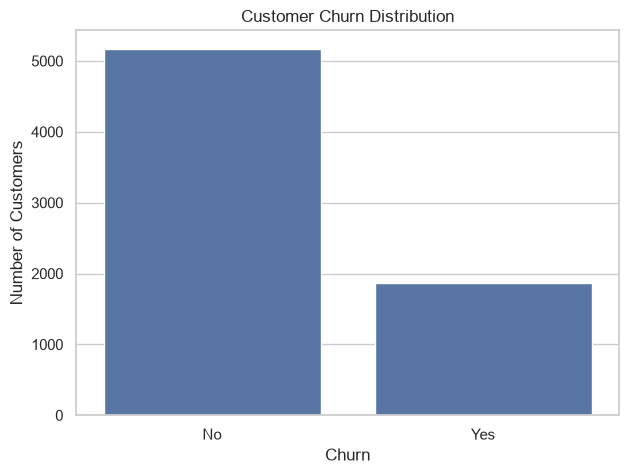

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

# Chart 2: Churn by gender

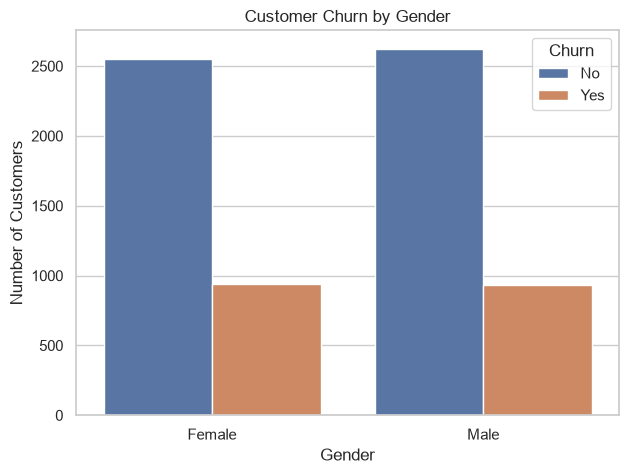

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="gender", hue="Churn")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

# Chart 3: Churn by contract type

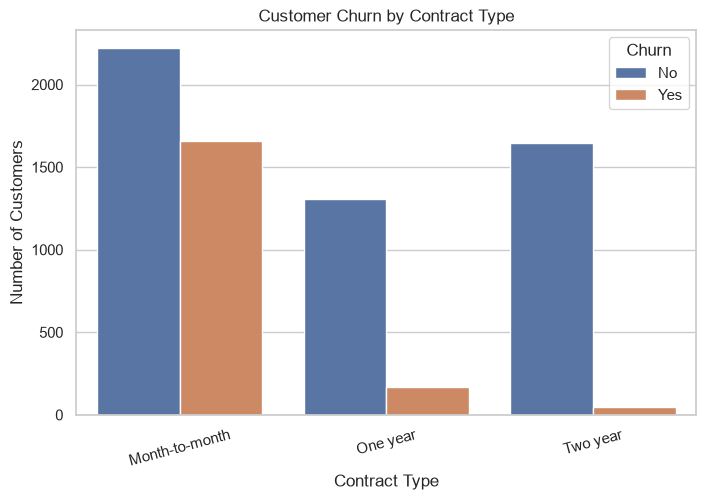

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

# Chart 4: Monthly charges by churn

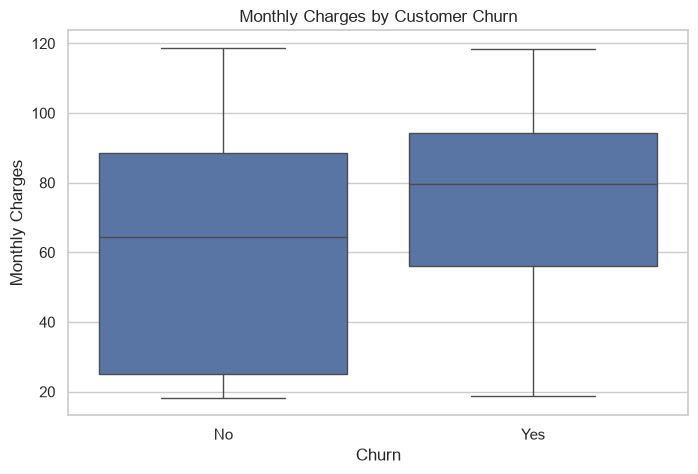

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

# Chart 5: Churn by internet service

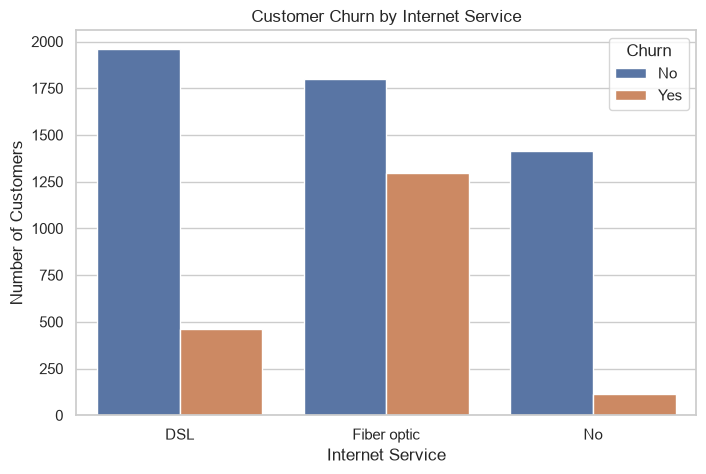

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

# Step 11: Correlation analysis

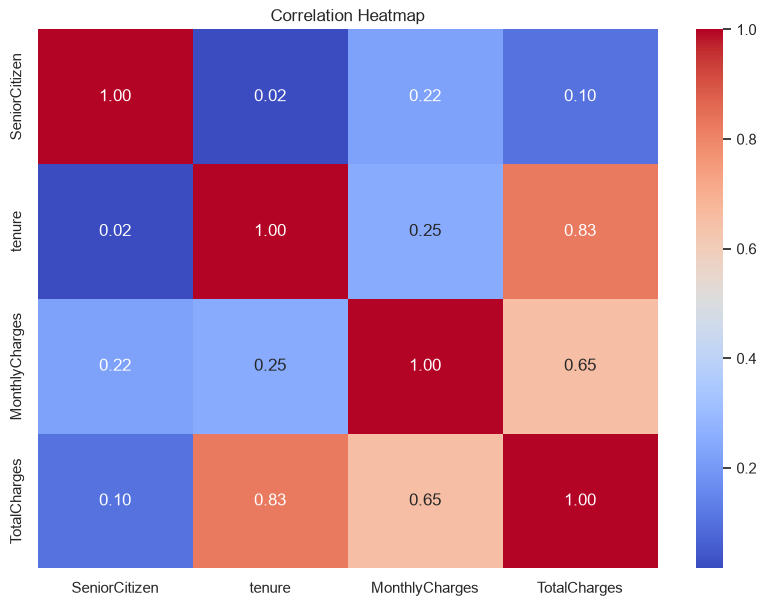

In [16]:
# Select numerical columns
numerical_df = df.select_dtypes(include=["number"])

# Calculate correlations
correlation = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# Step 12: Checking and fixing missing value

In [17]:
# Display customers with missing TotalCharges
missing_customers = df[df["TotalCharges"].isnull()]

display(
    missing_customers[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


# 4. Our next task: investigate the 11 missing values 

In [18]:
# Create a processed data folder
processed_folder = Path("data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
df.to_csv(
    processed_folder / "cleaned_customer_churn.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# 5. Calculate churn percentages

In [19]:
# Calculate customer churn percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

display(churn_percentage)


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# 3.Fix the missing values

In [20]:
# Replace missing TotalCharges values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


# 4. Verify the cleaning

In [21]:
# Check the 11 previously missing values
print("Customers with zero tenure:")
display(
    df[df["tenure"] == 0][
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

# Confirm missing values
print("Total missing values:", df.isnull().sum().sum())

Customers with zero tenure:


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,0.0
753,3115-CZMZD,0,20.25,0.0
936,5709-LVOEQ,0,80.85,0.0
1082,4367-NUYAO,0,25.75,0.0
1340,1371-DWPAZ,0,56.05,0.0
3331,7644-OMVMY,0,19.85,0.0
3826,3213-VVOLG,0,25.35,0.0
4380,2520-SGTTA,0,20.00,0.0
5218,2923-ARZLG,0,19.70,0.0
6670,4075-WKNIU,0,73.35,0.0


Total missing values: 0


# Step 13: Save your cleaned dataset
Now save the updated dataset:

In [22]:
from pathlib import Path

# Create processed data folder
processed_folder = Path("data/processed")
processed_folder.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
df.to_csv(
    processed_folder / "cleaned_customer_churn.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Conclusion

In this project, I explored the IBM Telco Customer Churn dataset to understand customer behaviour and identify factors associated with customer churn.

The analysis revealed that approximately 26.54% of customers had left the company.

I cleaned the dataset by converting the `TotalCharges` column into a numeric format and handling 11 missing values associated with customers who had zero months of tenure.

I also used data visualisations to explore customer churn across different categories, including contract types, gender, and internet services.

This analysis provides a starting point for understanding customer retention and identifying customers who may be at risk of leaving.

**Next Steps:**
- Investigate the factors that have the strongest relationship with customer churn.
- Build a machine learning model to predict customer churn.
- Identify ways the company could improve customer retention.

### Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.